# CSAD 模型（基于“小型”板块）

**用于构建羊群效应因子的行为金融模型**

① 每个月末，提取当前可交易股票过去 120 个交易日的涨跌幅数据，计算目标股票 $S_t$ 与其他股票（不活跃交易日不超过 20 天）之间的日涨跌幅相关系数；

② 选取与 $S_t$ 相关系数最大的 9 只股票，连同 $S_t$ 一起构成一个包含 10 只股票的“小型”板块：

$$
S_i,\quad i = 1, 2, \dots, 10
$$

③ 计算该板块过去 120 个交易日的横截面绝对偏差（CSAD）：

$$
\text{CSAD}_t = \frac{1}{10} \sum_{i=1}^{10} \left| r_{i,t} - \bar{r}_t \right|
$$

其中，$r_{i,t}$ 为板块内第 $i$ 只股票在交易日 $t$ 的收益率，$\bar{r}_t$ 为板块内所有股票在交易日 $t$ 的平均收益率。

④ 对 CSAD 进行时序标准化，并计算过去 20 个交易日的均值，作为羊群效应因子：

$$
Z_{jt} = \frac{\text{CSAD}_{jt} - \mu_{\text{CSAD}_j}}{\sigma_{\text{CSAD}_j}}
$$$$
f_{jt} = -\frac{1}{20} \sum_{k=1}^{20} Z_{j,t-k+1}
$$

其中，$j$ 表示第 $j$ 个“小型”板块，$\mu_{\text{CSAD}_j}$ 和 $\sigma_{\text{CSAD}_j}$ 分别为该板块 CSAD 在样本期内的均值和标准差，$Z_{jt}$ 为标准化后的 CSAD，$f_{jt}$ 为最终的羊群效应因子。

## 因子逻辑说明

CSAD 利用股票收益在横截面上的分散度来衡量市场羊群效应的强弱。为使因子对个股具备选股能力，该模型将与目标个股走势最为相近的股票组成“小型”板块，借助该小板块上的羊群效应强弱来近似反映该股票近期的关注度变化。

因子值 $f_{jt}$ 越大（由于负号处理，对应近期 CSAD 显著偏低），表明板块近期的羊群效应越强，板块内个股收益趋于一致，该板块受市场关注的程度提升越明显，未来收益预期也越高。

数据：日度收盘价

In [1]:
import numpy as np
import pandas as pd
from rqdatac import all_instruments, get_price, get_trading_dates

def _get_ids(stock_ids=None):
    """默认返回米筐 CS 股票全集。"""
    if stock_ids is not None:
        return list(dict.fromkeys(stock_ids))

    return (
        all_instruments("CS")
        .order_book_id
        .dropna()
        .drop_duplicates()
        .tolist()
    )

def _prepare_dates(start_date, end_date, lookback_days):
    """
    返回：
    target_dates：最终需要输出因子的交易日；
    price_dates：为计算滚动收益而额外向前展开后的价格日期。
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(days=max(lookback_days * 3, 90)),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < lookback_days:
        raise ValueError("历史交易日不足，无法满足滚动窗口。")

    price_dates = calendar[first_loc - lookback_days:last_loc + 1]
    return target_dates, price_dates


def _get_batch_close_volume(batch, price_dates):
    """
    米筐多标的查询不能使用 skip_suspended=True；
    因此下载成交量，并用 volume > 0 排除当日停牌股票。
    """
    raw = get_price(
        order_book_ids=batch,
        start_date=price_dates[0],
        end_date=price_dates[-1],
        frequency="1d",
        fields=["close", "volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None, None

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
        volume = raw["volume"].unstack("order_book_id")
    else:
        close = raw[["close"]].rename(columns={"close": batch[0]})
        volume = raw[["volume"]].rename(columns={"volume": batch[0]})

    close.index = pd.to_datetime(close.index)
    volume.index = pd.to_datetime(volume.index)

    return (
        close.reindex(index=price_dates, columns=batch),
        volume.reindex(index=price_dates, columns=batch),
    )

# 旧函数
# def _get_returns(close, volume):
#     """仅保留当日实际有成交的股票收益率。"""
#     returns = close.pct_change(fill_method=None).iloc[1:]
#     traded_today = volume.iloc[1:].gt(0)
#     return returns.where(traded_today)

# 新函数，只保留前后两个交易日均正常成交的日收益，避免复牌日后的异常涨幅
def _get_returns(close, volume):
    """只保留前后两个交易日均正常成交的日收益。"""
    returns = close.pct_change(fill_method=None).iloc[1:]

    traded_today = volume.iloc[1:].gt(0)
    traded_yesterday = volume.shift(1).iloc[1:].gt(0)

    valid_price = (
        close.iloc[1:].gt(0)
        & close.shift(1).iloc[1:].gt(0)
    )

    return returns.where(traded_today & traded_yesterday & valid_price)

def _stack_factor(factor_wide, factor_name):
    """日期 × 股票宽表转为 date、order_book_id 两层索引。"""
    panel = factor_wide.stack(dropna=True).rename(factor_name).to_frame()
    panel.index = panel.index.set_names(["date", "order_book_id"])
    return panel

def _download_returns_wide(order_book_ids, price_dates, batch_size=500):
    """
    分批下载收盘价与成交量，返回“日期 × 股票”的日收益率宽表。

    停牌或无成交日的收益率会保留为 NaN。
    """
    return_parts = []

    for start in range(0, len(order_book_ids), batch_size):
        batch = order_book_ids[start:start + batch_size]

        close, volume = _get_batch_close_volume(
            batch=batch,
            price_dates=price_dates,
        )

        if close is None:
            continue

        return_parts.append(_get_returns(close, volume))

    if not return_parts:
        raise RuntimeError("未取得有效价格数据。")

    returns = pd.concat(return_parts, axis=1)

    return (
        returns
        .reindex(index=price_dates[1:], columns=order_book_ids)
        .sort_index()
    )

def calculate_small_board_csad(
    start_date,
    end_date,
    candidate_ids=None,
    peer_universe_ids=None,
    corr_window=120,
    max_inactive_days=20,
    group_size=10,
    zscore_window=120,
    smooth_window=20,
    min_group_active=10,
    batch_size=500,
):
    """
    基于“小型”板块的 CSAD 羊群效应因子。

    返回
    ----
    DataFrame
        MultiIndex：date、order_book_id
        Column：SMALL_BOARD_CSAD

    因子值越大：
        表示近期板块 CSAD 越低、股票走势越趋同、羊群效应越强。
    """
    if group_size < 2:
        raise ValueError("group_size 至少为 2。")

    if min_group_active > group_size:
        raise ValueError("min_group_active 不能大于 group_size。")

    if corr_window <= max_inactive_days:
        raise ValueError("corr_window 必须大于 max_inactive_days。")

    # 第一个输出日需要：
    # 1）120 日相关性历史；
    # 2）120 日 CSAD 标准化历史；
    # 3）20 日 Z 值平滑历史；
    # 4）预留一个月，确保存在上一个月末的分组。
    required_lookback = (
        corr_window + zscore_window + smooth_window + 25
    )

    target_dates, price_dates = _prepare_dates(
        start_date=start_date,
        end_date=end_date,
        lookback_days=required_lookback,
    )

    candidate_ids = _get_ids(candidate_ids)
    peer_universe_ids = _get_ids(peer_universe_ids)

    # 目标股票必须包含在找同伴的股票池中。
    peer_universe_ids = list(dict.fromkeys(
        peer_universe_ids + candidate_ids
    ))

    # 日期 × 股票 的收益率宽表。
    returns = _download_returns_wide(
        order_book_ids=peer_universe_ids,
        price_dates=price_dates,
        batch_size=batch_size,
    )

    work_dates = returns.index
    target_date_set = set(target_dates)

    factor_wide = pd.DataFrame(
        np.nan,
        index=target_dates,
        columns=candidate_ids,
    )

    # 找到每个月最后一个交易日。
    month_end_dates = pd.DatetimeIndex(
        pd.Series(
            work_dates,
            index=work_dates.to_period("M"),
        )
        .groupby(level=0)
        .max()
        .values
    )

    min_corr_observations = corr_window - max_inactive_days

    for rebalance_pos, rebalance_date in enumerate(month_end_dates):
        date_pos = work_dates.get_loc(rebalance_date)

        # 没有足够的 120 日收益率历史时，无法建立小型板块。
        if date_pos + 1 < corr_window:
            continue

        correlation_returns = returns.iloc[
            date_pos - corr_window + 1:date_pos + 1
        ]

        valid_count = correlation_returns.notna().sum(axis=0)

        eligible_ids = valid_count[
            valid_count >= min_corr_observations
        ].index.tolist()

        if len(eligible_ids) < group_size:
            continue

        # 只用近期活跃且窗口内缺失不超过 max_inactive_days 的股票计算相关性。
        corr_matrix = correlation_returns[
            eligible_ids
        ].corr(min_periods=min_corr_observations)

        current_candidates = [
            stock for stock in candidate_ids
            if (
                stock in eligible_ids
                and pd.notna(returns.loc[rebalance_date, stock])
            )
        ]

        # 本月末形成的板块，持续到下个月末前。
        if rebalance_pos < len(month_end_dates) - 1:
            next_rebalance_date = month_end_dates[rebalance_pos + 1]
            effective_dates = work_dates[
                (work_dates >= rebalance_date)
                & (work_dates < next_rebalance_date)
            ]
        else:
            effective_dates = work_dates[
                work_dates >= rebalance_date
            ]

        output_dates = [
            date for date in effective_dates
            if date in target_date_set
        ]

        if not output_dates:
            continue

        for stock in current_candidates:
            peer_corr = (
                corr_matrix[stock]
                .drop(index=stock, errors="ignore")
                .dropna()
                .sort_values(ascending=False)
            )

            peers = peer_corr.head(group_size - 1).index.tolist()

            if len(peers) < group_size - 1:
                continue

            small_board = [stock] + peers
            board_returns = returns[small_board]

            # 每日板块平均收益与 CSAD。
            board_mean_return = board_returns.mean(axis=1, skipna=True)
            active_count = board_returns.notna().sum(axis=1)

            csad = (
                board_returns.sub(board_mean_return, axis=0)
                .abs()
                .mean(axis=1, skipna=True)
            ).where(active_count >= min_group_active)

            # 使用截至当天的滚动均值与标准差标准化。
            rolling_mean = csad.rolling(
                window=zscore_window,
                min_periods=zscore_window,
            ).mean()

            rolling_std = csad.rolling(
                window=zscore_window,
                min_periods=zscore_window,
            ).std(ddof=0)

            zscore = (
                (csad - rolling_mean)
                / rolling_std.replace(0, np.nan)
            )

            # 加负号：CSAD 越低，因子越高，代表羊群越强。
            factor_series = -zscore.rolling(
                window=smooth_window,
                min_periods=smooth_window,
            ).mean()

            factor_wide.loc[
                output_dates, stock
            ] = factor_series.reindex(output_dates).values

    return _stack_factor(factor_wide, "SMALL_BOARD_CSAD")

In [2]:
# from rqdatac import index_components

# # 沪深300成分股

# stock_pool = index_components(
#     "000300.XSHG",
#     date="2025-12-31",
# )

# small_board_csad_panel = calculate_small_board_csad(
#     start_date="2020-01-01",
#     end_date="2025-12-31",
#     candidate_ids=stock_pool,
#     peer_universe_ids=stock_pool,
#     corr_window=120,
#     max_inactive_days=20,
#     group_size=10,
#     zscore_window=120,
#     smooth_window=20,
# )

# small_board_csad_panel

> 当前函数中，candidate_ids=None 与 peer_universe_ids=None 就表示使用 _get_ids(None) 返回的全股票池。但全 A 版本会明显更慢：每个月末都要计算约 $N \times N$ 的相关系数矩阵。若当时有 5,000 只可用股票，就约有 2,500 万个相关系数；batch_size 只能减少下载行情时的请求压力，不能降低这一步的平方级计算量。
建议先按年运行，避免 Notebook 长时间占用内存.


```python
all_a_parts = []

for year in [2024, 2025]:
    factor_part = calculate_small_board_csad(
        start_date="{}-01-01".format(year),
        end_date="{}-12-31".format(year),
        candidate_ids=None,
        peer_universe_ids=None,
        corr_window=120,
        max_inactive_days=20,
        group_size=10,
        zscore_window=120,
        smooth_window=20,
        min_group_active=10,
        batch_size=500,
    )

    all_a_parts.append(factor_part)

small_board_csad_all_a = pd.concat(all_a_parts).sort_index()
```

这里每年单独运行仍然正确：函数会自动额外下载足够的历史交易日，用于相关性、CSAD 标准化和 20 日平滑窗口。

In [ ]:
# 计算量非常大

all_a_parts = []

for year in [2020, 2021, 2022, 2023, 2024, 2025]:
    factor_part = calculate_small_board_csad(
        start_date="{}-01-01".format(year),
        end_date="{}-12-31".format(year),
        candidate_ids=None,
        peer_universe_ids=None,
        corr_window=120,
        max_inactive_days=20,
        group_size=10,
        zscore_window=120,
        smooth_window=20,
        min_group_active=10,
        batch_size=500,
    )
    print(1)

    all_a_parts.append(factor_part)

small_board_csad_all_a = pd.concat(all_a_parts).sort_index()

In [ ]:
small_board_csad_all_a

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rqdatac import get_trading_dates

factor_name = "SMALL_BOARD_CSAD"
start_date = "2020-01-01"
end_date = "2025-12-31"
review_threshold = 3.0

panel = small_board_csad_all_a[[factor_name]].copy()
panel.index = panel.index.set_names(["date", "order_book_id"])
panel.index = panel.index.set_levels(
    pd.to_datetime(panel.index.levels[0]),
    level="date",
)

values = pd.to_numeric(panel[factor_name], errors="coerce")
valid = values.replace([np.inf, -np.inf], np.nan).dropna()

if valid.empty:
    raise ValueError("没有有效的 SMALL_BOARD_CSAD 因子值。")

target_dates = pd.DatetimeIndex(
    get_trading_dates(start_date=start_date, end_date=end_date)
)

duplicate_count = int(panel.index.duplicated().sum())
explicit_missing = int(values.isna().sum())
inf_count = int(np.isinf(values.dropna().values).sum())

# 每个交易日的横截面统计；没有因子输出的交易日也保留为 0。
by_date = values.groupby(level="date").agg(
    因子股票数="count",
    均值="mean",
    标准差="std",
    最小值="min",
    中位数="median",
    最大值="max",
)

quantiles = values.groupby(level="date").quantile(
    [0.01, 0.05, 0.95, 0.99]
).unstack()

quantiles.columns = ["P01", "P05", "P95", "P99"]

by_date = pd.DataFrame(index=target_dates).join(by_date).join(quantiles)
by_date.index.name = "date"
by_date["因子股票数"] = by_date["因子股票数"].fillna(0)
by_date["年份"] = by_date.index.year

# 使用“同年度每日因子股票数中位数”作为可构建板块数量的动态基准。
year_median_count = by_date.groupby("年份")["因子股票数"].transform("median")
by_date["相对覆盖率"] = (
    by_date["因子股票数"]
    / year_median_count.replace(0, np.nan)
)

stock_observations = values.groupby(level="order_book_id").count()

suspicious = (
    panel.loc[values.abs() > review_threshold]
    .sort_values(factor_name, key=lambda x: x.abs(), ascending=False)
)

summary = pd.DataFrame({
    "指标": [
        "目标交易日数",
        "有至少一个因子值的交易日数",
        "完全无输出交易日数",
        "实际有效观测数",
        "覆盖股票数",
        "重复 date-stock",
        "显式缺失值",
        "无穷值",
        "每日因子股票数均值",
        "每日因子股票数 P05",
        "相对覆盖率 P05",
        "单股有效天数 P05",
        "因子均值",
        "因子标准差",
        "最小值",
        "P01",
        "中位数",
        "P99",
        "最大值",
        "|因子值| > 3 的观测数",
    ],
    "数值": [
        len(target_dates),
        int((by_date["因子股票数"] > 0).sum()),
        int((by_date["因子股票数"] == 0).sum()),
        len(valid),
        values.index.get_level_values("order_book_id").nunique(),
        duplicate_count,
        explicit_missing,
        inf_count,
        by_date["因子股票数"].mean(),
        by_date["因子股票数"].quantile(0.05),
        by_date["相对覆盖率"].quantile(0.05),
        stock_observations.quantile(0.05),
        valid.mean(),
        valid.std(),
        valid.min(),
        valid.quantile(0.01),
        valid.median(),
        valid.quantile(0.99),
        valid.max(),
        int((valid.abs() > review_threshold).sum()),
    ],
    "判断": [
        "",
        "应接近目标交易日数",
        "应为 0；否则需检查分组或滚动窗口",
        "",
        "",
        "应为 0",
        "最终 stack 后通常应为 0",
        "应为 0",
        "",
        "检查极端低覆盖日期",
        "建议大于 0.80；过低常由停牌或 min_group_active=10 导致",
        "检查是否有股票长期无法形成完整 10 股票板块",
        "滚动 Z 分数平滑后通常接近 0，但不要求严格为 0",
        "",
        "因子可为负，不是错误",
        "",
        "",
        "",
        "因子可为正或负",
        "用于复核滚动标准差过小、异常板块或数据问题",
    ],
})

display(summary)
display(by_date.tail())
display(suspicious.head(20))

# ---------- 分布图 ----------
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
})

p01, p50, p99 = valid.quantile([0.01, 0.50, 0.99]).values

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左图：全部 date-stock 因子值的分布
axes[0].hist(valid.values, bins=80, color="#4C78A8", alpha=0.85)
axes[0].axvline(0, color="#222222", linewidth=1)
axes[0].axvline(
    p01, color="#59A14F", linestyle="--",
    label="P01: {:.2f}".format(p01),
)
axes[0].axvline(
    p50, color="#F28E2B", linestyle="--",
    label="Median: {:.2f}".format(p50),
)
axes[0].axvline(
    p99, color="#E15759", linestyle="--",
    label="P99: {:.2f}".format(p99),
)
axes[0].set_title("Small-board CSAD Factor Distribution")
axes[0].set_xlabel("SMALL_BOARD_CSAD")
axes[0].set_ylabel("Count")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[0].set_axisbelow(True)

# 右图：每日横截面均值与 5%—95% 区间
plot_data = by_date.dropna(subset=["均值", "P05", "P95"])

axes[1].plot(
    plot_data.index,
    plot_data["均值"],
    color="#4C78A8",
    linewidth=1.1,
    label="Cross-sectional mean",
)

axes[1].fill_between(
    plot_data.index,
    plot_data["P05"].values,
    plot_data["P95"].values,
    color="#4C78A8",
    alpha=0.20,
    label="P05-P95 range",
)

axes[1].axhline(0, color="#222222", linewidth=1, linestyle="--")
axes[1].set_title("Daily Cross-sectional Distribution")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("SMALL_BOARD_CSAD")
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.25)
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.show()

# 如需保存：
# plt.savefig("small_board_csad_all_a_distribution.png", dpi=200, bbox_inches="tight")

# 这里 SMALL_BOARD_CSAD > 0 表示近期 20 日平均 CSAD 低于该板块自身过去 120 日常态，即收益趋同增强；负值则表示近期板块收益分歧扩大。

结论：最终因子输出在完整性和数值分布上通过，且“小型板块 CSAD”的负偏态是符合金融逻辑的。

- 1,455 个交易日每天都有因子输出，没有日期断档；
- 510.25 万个有效观测、5,325 只股票，无重复、缺失或无穷值；
- 每日有效股票数均值约 3,507；即使覆盖较低的 5% 日期，仍达到同年度正常水平的 93.1%，说明低覆盖主要是早期市场股票数量较少，而非计算故障；
- 单股有效天数 P05 为 339 天，符合新股需要积累相关性窗口、CSAD 标准化窗口和 20 日平滑窗口后才能产生因子的设定。

数值分布也合理：

- 均值 `-0.175`、中位数 `-0.060`、标准差 `0.611`；
- 99% 分位数为 `+0.812`，最大值 `+1.539`；
- 1% 分位数为 `-1.956`，最小值 `-3.849`；
- `|因子值| > 3` 仅 681 条，占全部观测约 **0.013%**。

分布呈现明显左偏：负尾更长、正尾较短。这是合理的。CSAD 有零下界，但在高波动、强分歧行情下可以显著上升；因此：

- 板块 CSAD 突然显著升高 → Z 分数很高 → 加负号后的因子出现较大负值；
- 板块 CSAD 降低 → 因子为正，但 CSAD 不可能低于零，正向极端天然受到限制。

所以 `-3.85` 并不意味着“极端羊群”，恰好相反：它表示近期板块收益分歧远高于自身历史常态。`+1.54` 才表示较强的收益趋同、羊群效应候选状态。

异常清单中 `002105.XSHE` 在 2024 年 1 月连续多日出现较大负值，也符合 20 日平滑的机制：一次或一段持续的高 CSAD 会在后续多个交易日继续影响平滑因子，并非重复数据。

> `all_instruments("CS")` 不传日期时返回的是**全部股票合约基础信息**，包含退市股票；官方示例中 `000024.XSHE` 就显示为 `status='Delisted'`
当前全 A 构造不再有“只使用现存股票”的幸存者偏差。
结合你的实现：
- 上市前没有有效价格/成交，无法满足相关性与 CSAD 滚动窗口，自然不会产生因子；
- 退市后也没有后续有效收益，无法继续满足 10 只活跃股票条件，因子会自然停止；
- 因此 candidate_ids=None 与 peer_universe_ids=None 的全 A 口径在历史上是合理的。

In [ ]:
small_board_csad_all_a_df = (
    small_board_csad_all_a["SMALL_BOARD_CSAD"]
    .unstack("order_book_id")
    .sort_index()
)

small_board_csad_all_a_df.index = pd.to_datetime(small_board_csad_all_a_df.index)
small_board_csad_all_a_df.columns.name = "order_book_id"

small_board_csad_all_a_df.to_csv("small_board_csad_all_a_df.csv", index=True)

In [1]:
import pandas as pd

small_board_csad_factor_data = pd.read_csv(
    "small_board_csad_all_a_df.csv",
    index_col=0,
    parse_dates=True,
)

# 恢复米筐因子测试所需的格式
small_board_csad_factor_data.index = pd.to_datetime(
    small_board_csad_factor_data.index
)
small_board_csad_factor_data.index.name = "date"

small_board_csad_factor_data.columns = (
    small_board_csad_factor_data.columns.astype(str)
)
small_board_csad_factor_data.columns.name = "order_book_id"

small_board_csad_factor_data = (
    small_board_csad_factor_data
    .apply(pd.to_numeric, errors="coerce")
    .sort_index()
)

print(small_board_csad_factor_data.shape)
small_board_csad_factor_data

(1455, 5325)


order_book_id,000001.XSHE,000002.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,000011.XSHE,...,688787.XSHG,688788.XSHG,688789.XSHG,688793.XSHG,688798.XSHG,688799.XSHG,688800.XSHG,688819.XSHG,688981.XSHG,689009.XSHG
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,0.365413,-0.032376,NaN,0.189487,0.795130,NaN,0.450517,NaN,0.242131,0.769459,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.288481,-0.082385,NaN,0.155579,0.735061,NaN,0.479483,NaN,0.162629,0.729496,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,0.315012,-0.176280,NaN,0.147249,0.714749,NaN,0.354905,NaN,0.137401,0.728341,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,0.370996,-0.063445,NaN,0.065395,0.645385,NaN,0.333681,NaN,0.010104,0.649611,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,0.320810,-0.121314,NaN,0.057630,0.649329,NaN,0.289068,NaN,-0.050492,0.646576,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,0.087482,-0.104981,-0.761712,NaN,0.074932,-0.939365,-0.439835,0.537365,0.216867,0.443383,...,0.270408,NaN,0.055294,-0.063619,0.330424,0.760216,-0.264726,NaN,NaN,-0.080655
2025-12-26,0.026890,0.012332,-0.791645,NaN,0.042804,-1.022304,-0.408210,0.508379,0.220085,0.438390,...,0.200177,NaN,0.050686,-0.397896,0.339578,0.750350,-0.313541,NaN,NaN,-0.071914
2025-12-29,0.034227,0.070623,-0.771416,NaN,0.063836,-0.937186,-0.532846,0.495514,0.240477,0.468286,...,0.261640,NaN,0.103983,-0.291364,0.431654,0.769083,-0.310452,NaN,NaN,-0.234290


In [2]:
from rqfactor.notebook import factor_analysis

result_small_board_csad_all_a = factor_analysis(
    f=small_board_csad_factor_data,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=10,
    ascending=False,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)
result_small_board_csad_all_a.show()

Loading BokehJS ...

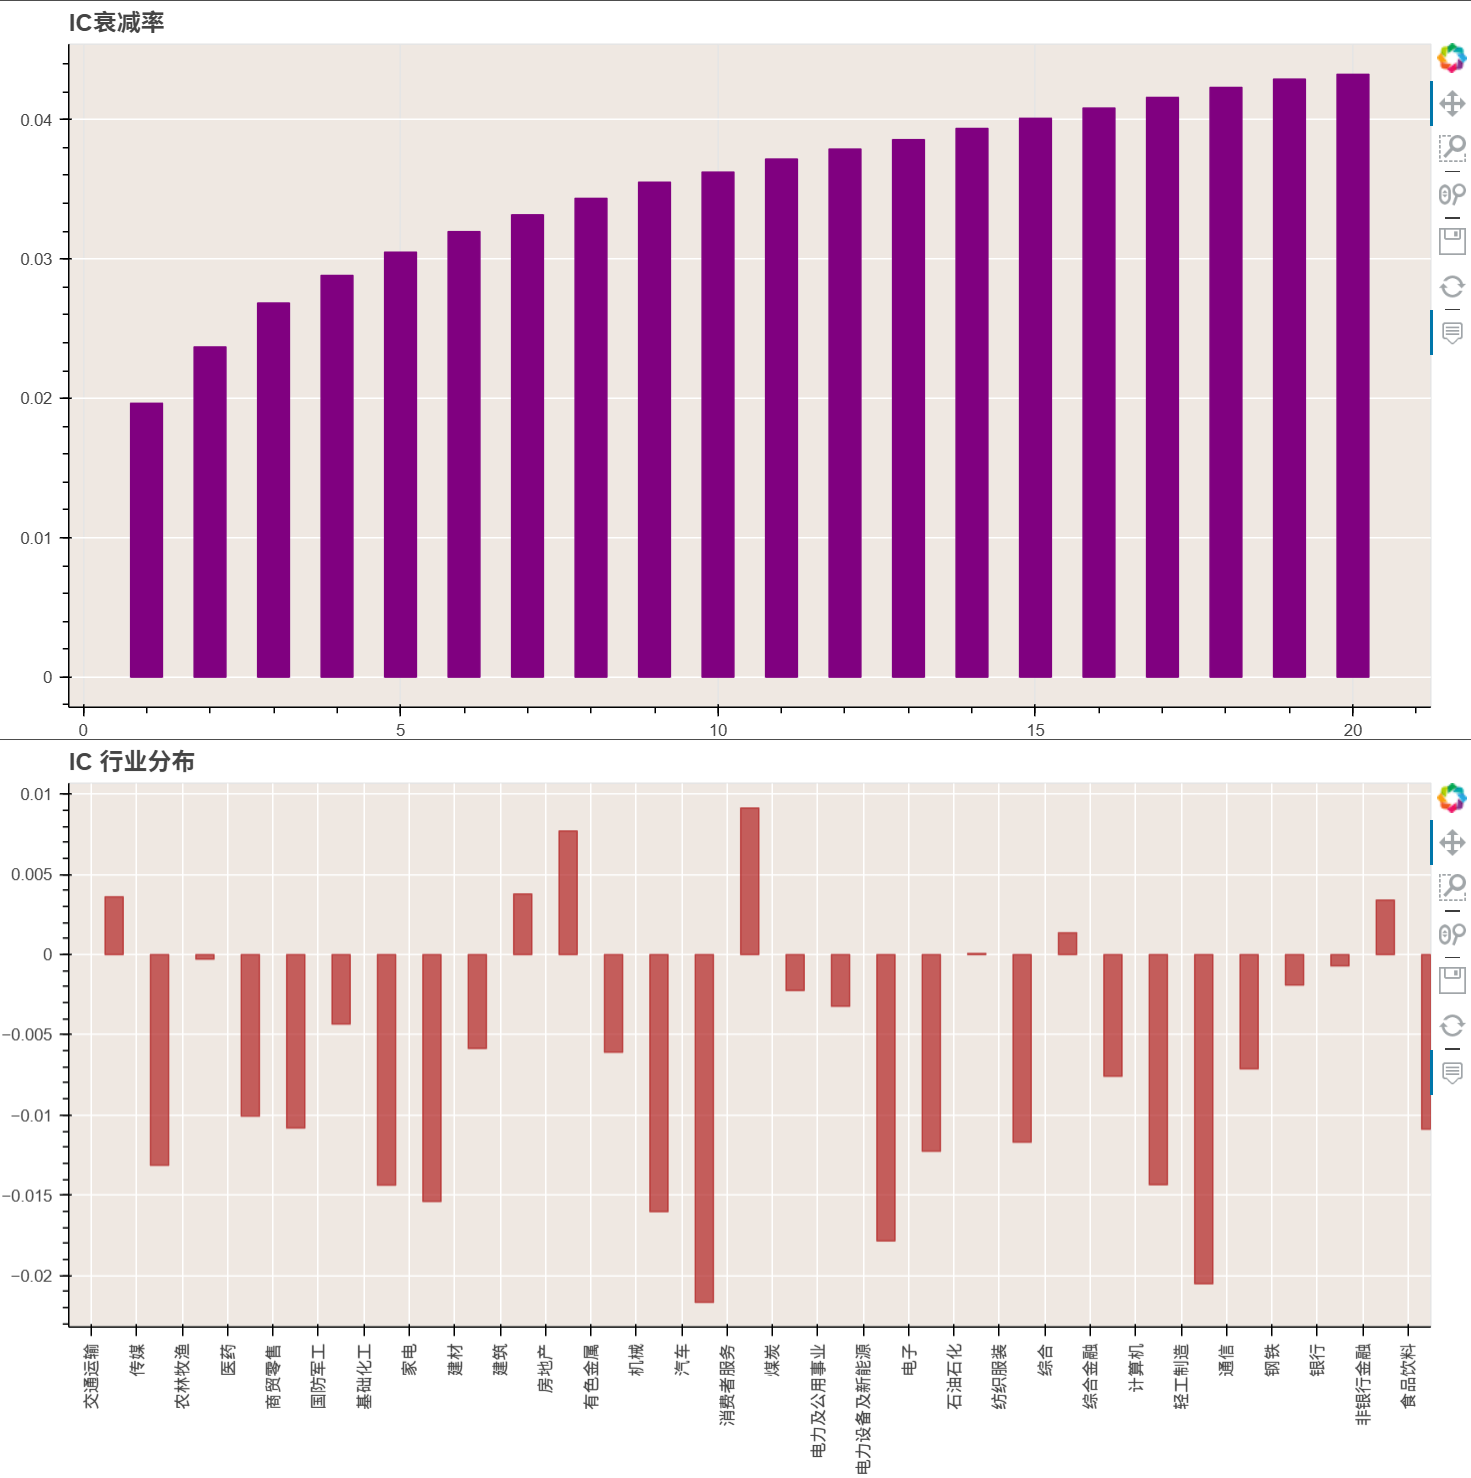

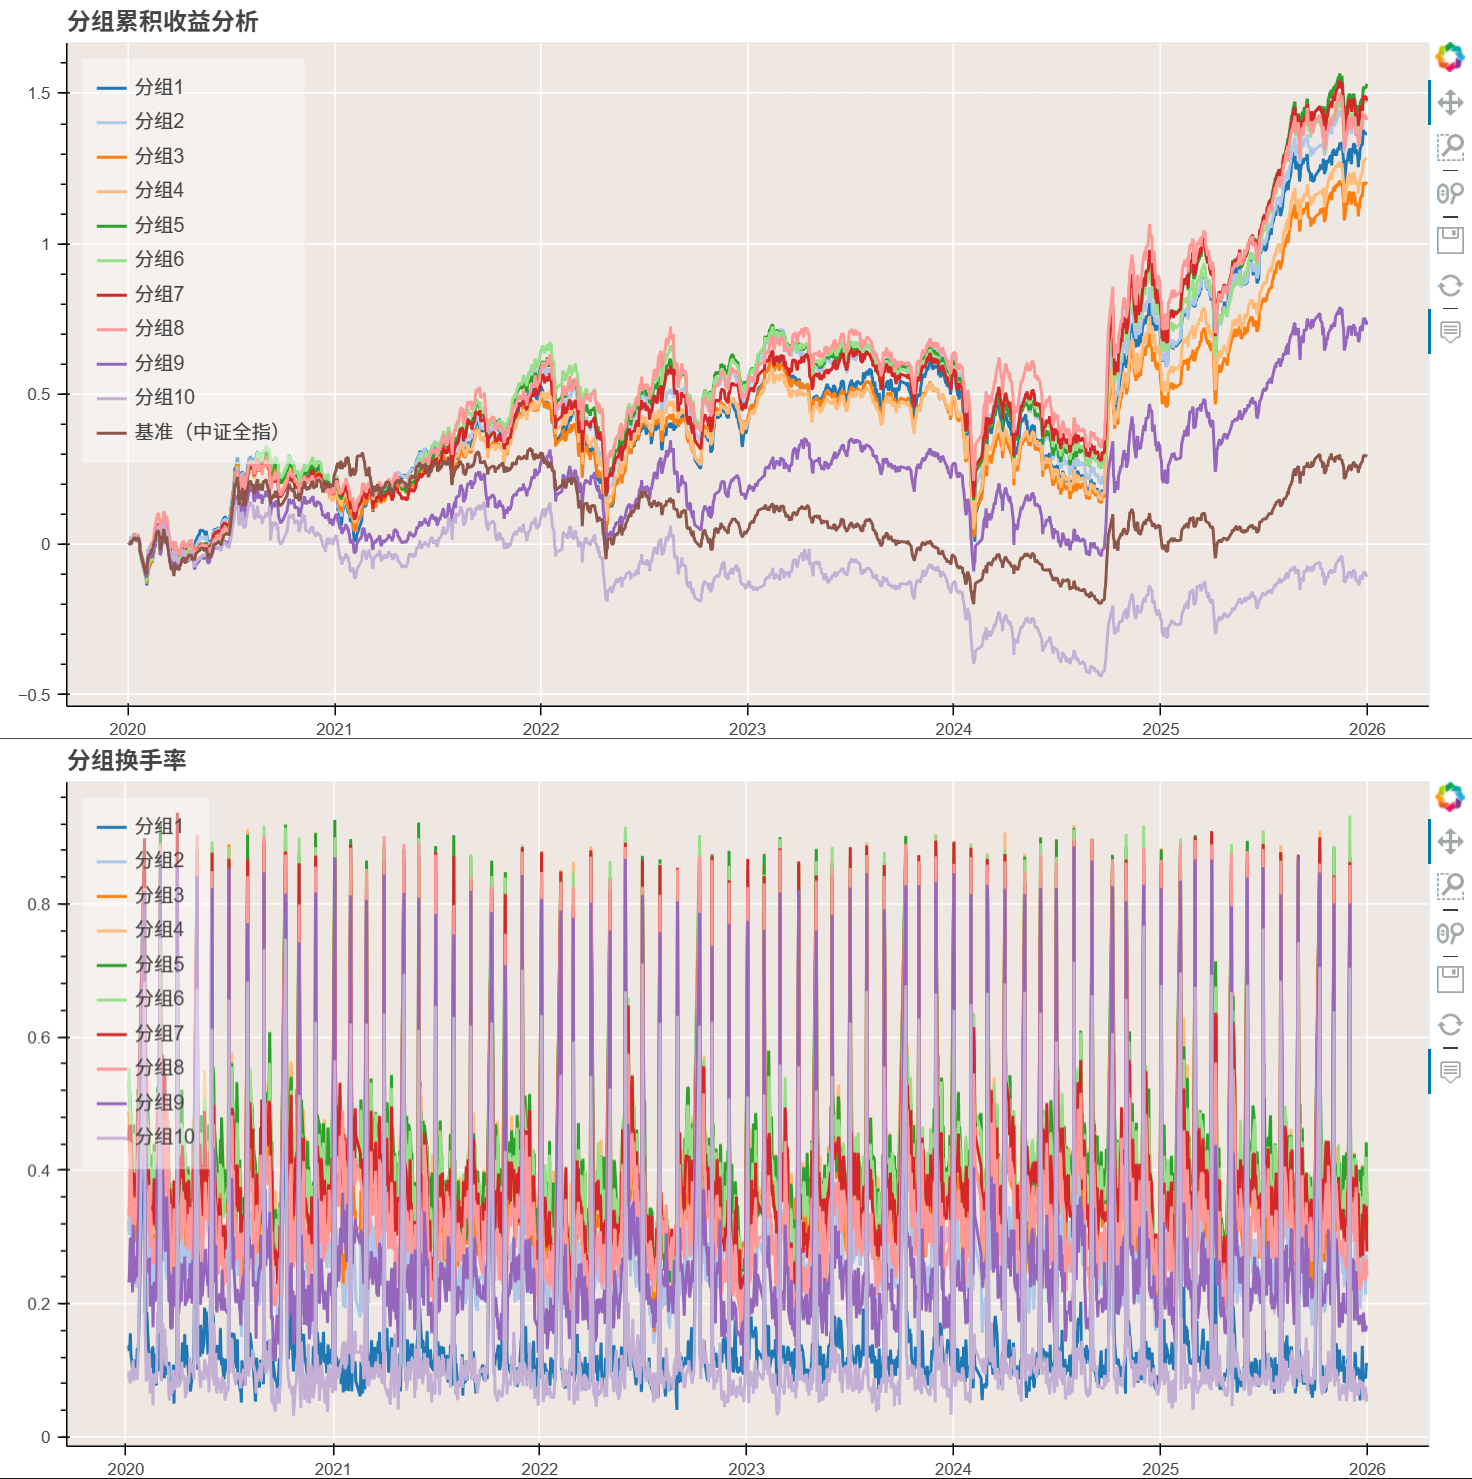

In [12]:
import numpy as np
import pandas as pd
from scipy import stats
from rqdatac import get_price

TRADING_DAYS = 252
RISK_FREE_RATE = 0.0     # 若有无风险利率序列，可替换为日频无风险收益
BENCHMARK = "000985.XSHG"

# ========== 1. IC 指标 ==========
result = result_small_board_csad_all_a
ic = result.ic.dropna()

ic_t_stat, ic_p_value = stats.ttest_1samp(ic, 0)

ic_metrics = pd.Series({
    "样本天数": len(ic),
    "平均 Rank IC": ic.mean(),
    "Rank IC 标准差": ic.std(ddof=1),
    "日频 ICIR": ic.mean() / ic.std(ddof=1),
    "年化 ICIR": ic.mean() / ic.std(ddof=1) * np.sqrt(TRADING_DAYS),
    "IC t 值": ic_t_stat,
    "IC p 值": ic_p_value,
    "正 IC 占比": (ic > 0).mean(),
    "负 IC 占比": (ic < 0).mean(),
    "IC 偏度": ic.skew(),
    "IC 峰度": ic.kurtosis(),
    "IC 一阶自相关": ic.autocorr(lag=1),
    "累计 Rank IC": ic.cumsum().iloc[-1],
})

display(ic_metrics.to_frame("Result"))

# ========== 2. 从米筐分组累计收益恢复日收益 ==========
# 米筐格式：行=q0~q9，列=日期，值=累计收益率
group_cumret = result.quantile_factor_returns.T.copy()
group_cumret.index = pd.to_datetime(group_cumret.index)
group_cumret = group_cumret.sort_index()

# 累计收益率 -> 净值 -> 日收益率
group_nav = 1 + group_cumret
group_daily_ret = group_nav.pct_change().dropna(how="all")

# 换手率
group_turnover = result.quantile_turnover.T.copy()
group_turnover.index = pd.to_datetime(group_turnover.index)
group_turnover = group_turnover.reindex(group_daily_ret.index)

# ========== 3. 下载基准日收益 ==========
from rqdatac import get_price

BENCHMARK = "000985.XSHG"

benchmark_price = get_price(
    BENCHMARK,
    start_date=group_daily_ret.index.min(),
    end_date=group_daily_ret.index.max(),
    frequency="1d",
    fields="close",
    adjust_type="pre",
    expect_df=True,
)

benchmark_close = benchmark_price["close"]

# 米筐可能返回 date × order_book_id 两层索引
if isinstance(benchmark_close.index, pd.MultiIndex):
    benchmark_close = (
        benchmark_close
        .unstack("order_book_id")
        .iloc[:, 0]
    )

benchmark_close.index = pd.to_datetime(benchmark_close.index)

benchmark_ret = (
    benchmark_close
    .pct_change()
    .reindex(group_daily_ret.index)
)

# ========== 4. 单个组合完整绩效指标 ==========
def performance_metrics(daily_ret, benchmark_ret=None, annual_rf=0.0):
    daily_ret = daily_ret.dropna()

    rf_daily = (1 + annual_rf) ** (1 / TRADING_DAYS) - 1
    excess_ret = daily_ret - rf_daily

    nav = (1 + daily_ret).cumprod()
    annual_return = nav.iloc[-1] ** (TRADING_DAYS / len(daily_ret)) - 1
    annual_volatility = daily_ret.std(ddof=1) * np.sqrt(TRADING_DAYS)

    sharpe = (
        excess_ret.mean() / daily_ret.std(ddof=1) * np.sqrt(TRADING_DAYS)
        if daily_ret.std(ddof=1) > 0 else np.nan
    )

    downside_volatility = (
        np.sqrt(np.mean(np.minimum(excess_ret, 0) ** 2))
        * np.sqrt(TRADING_DAYS)
    )
    sortino = (
        excess_ret.mean() * TRADING_DAYS / downside_volatility
        if downside_volatility > 0 else np.nan
    )

    drawdown = nav / nav.cummax() - 1
    max_drawdown = drawdown.min()

    calmar = (
        annual_return / abs(max_drawdown)
        if max_drawdown < 0 else np.nan
    )

    output = {
        "累计收益率": nav.iloc[-1] - 1,
        "年化收益率": annual_return,
        "年化波动率": annual_volatility,
        "夏普比率": sharpe,
        "Sortino 比率": sortino,
        "最大回撤": max_drawdown,
        "Calmar 比率": calmar,
        "日胜率": (daily_ret > 0).mean(),
        "平均日收益": daily_ret.mean(),
        "日收益偏度": daily_ret.skew(),
        "日收益峰度": daily_ret.kurtosis(),
    }

    if benchmark_ret is not None:
        pair = pd.concat(
            [daily_ret.rename("strategy"), benchmark_ret.rename("benchmark")],
            axis=1,
        ).dropna()

        r = pair["strategy"]
        b = pair["benchmark"]

        beta = np.cov(r, b, ddof=1)[0, 1] / np.var(b, ddof=1)
        alpha_daily = (
            (r - rf_daily).mean()
            - beta * (b - rf_daily).mean()
        )

        active_ret = r - b
        tracking_error = active_ret.std(ddof=1) * np.sqrt(TRADING_DAYS)
        information_ratio = (
            active_ret.mean() / active_ret.std(ddof=1)
            * np.sqrt(TRADING_DAYS)
        )

        relative_nav = ((1 + r) / (1 + b)).cumprod()
        annual_excess_return = (
            relative_nav.iloc[-1] ** (TRADING_DAYS / len(pair)) - 1
        )

        output.update({
            "基准年化收益率": (
                (1 + b).prod() ** (TRADING_DAYS / len(b)) - 1
            ),
            "年化超额收益": annual_excess_return,
            "Alpha（年化）": (1 + alpha_daily) ** TRADING_DAYS - 1,
            "Beta": beta,
            "跟踪误差": tracking_error,
            "信息比率": information_ratio,
        })

    return pd.Series(output)

# ========== 5. 十组组合的完整指标 ==========
group_metrics = pd.DataFrame({
    group: performance_metrics(
        group_daily_ret[group],
        benchmark_ret,
        annual_rf=RISK_FREE_RATE,
    )
    for group in group_daily_ret.columns
}).T

# 十个分组每日等权，得到全体股票池的总体收益序列
total_daily_ret = group_daily_ret.mean(axis=1)

# 总体累计收益曲线 / 净值曲线
total_nav = (1 + total_daily_ret).cumprod()
total_cumret = total_nav - 1

# 在分组指标表追加 total 行
group_metrics.loc["total"] = performance_metrics(
    total_daily_ret,
    benchmark_ret,
    annual_rf=RISK_FREE_RATE,
)

display(group_metrics.round(4))

,Result
样本天数,1.454000e+03
平均 Rank IC,1.964670e-02
Rank IC 标准差,1.380098e-01
日频 ICIR,1.423573e-01
年化 ICIR,2.259851e+00
IC t 值,5.428275e+00
IC p 值,6.659465e-08
正 IC 占比,5.557084e-01
负 IC 占比,4.442916e-01
IC 偏度,6.426626e-02


,累计收益率,年化收益率,年化波动率,夏普比率,Sortino 比率,最大回撤,Calmar 比率,日胜率,平均日收益,日收益偏度,日收益峰度,基准年化收益率,年化超额收益,Alpha（年化）,Beta,跟踪误差,信息比率
q0,1.3658,0.1611,0.2609,0.7038,0.9816,-0.3808,0.4230,0.5430,0.0007,-0.5119,9.4685,0.0453,0.1098,0.1184,1.0994,0.1413,0.8377
q1,1.4744,0.1702,0.2451,0.7646,1.0606,-0.3650,0.4661,0.5451,0.0007,-0.6326,10.0405,0.0453,0.1185,0.1248,1.0706,0.1195,1.0225
q2,1.2063,0.1471,0.2387,0.6953,0.9543,-0.3675,0.4002,0.5361,0.0007,-0.6974,9.3963,0.0453,0.0962,0.1015,1.0586,0.1102,0.9123
q3,1.2852,0.1541,0.2362,0.7259,0.9988,-0.3357,0.4590,0.5478,0.0007,-0.6638,9.1098,0.0453,0.1030,0.1075,1.0603,0.1039,1.0203
q4,1.5322,0.1748,0.2361,0.8016,1.1028,-0.3365,0.5196,0.5444,0.0008,-0.6789,9.1929,0.0453,0.1226,0.1270,1.0627,0.1027,1.2033
q5,1.4751,0.1702,0.2366,0.7836,1.0735,-0.3279,0.5190,0.5471,0.0007,-0.7168,8.8896,0.0453,0.1179,0.1221,1.0685,0.1017,1.1758
q6,1.4853,0.1710,0.2374,0.7848,1.0795,-0.2990,0.5721,0.5492,0.0007,-0.6559,8.0433,0.0453,0.1193,0.1238,1.0664,0.1043,1.1598
q7,1.4203,0.1657,0.2452,0.7486,1.0293,-0.2978,0.5564,0.5403,0.0007,-0.6050,7.0302,0.0453,0.1135,0.1188,1.0838,0.1152,1.0223
q8,0.7432,0.1012,0.2536,0.5078,0.6908,-0.3281,0.3084,0.5416,0.0005,-0.6068,5.9946,0.0453,0.0523,0.0587,1.0962,0.1282,0.4936
q9,-0.1020,-0.0185,0.2761,0.0712,0.0961,-0.5103,-0.0362,0.5382,0.0001,-0.4344,4.4384,0.0453,-0.0629,-0.0526,1.1129,0.1643,-0.2844


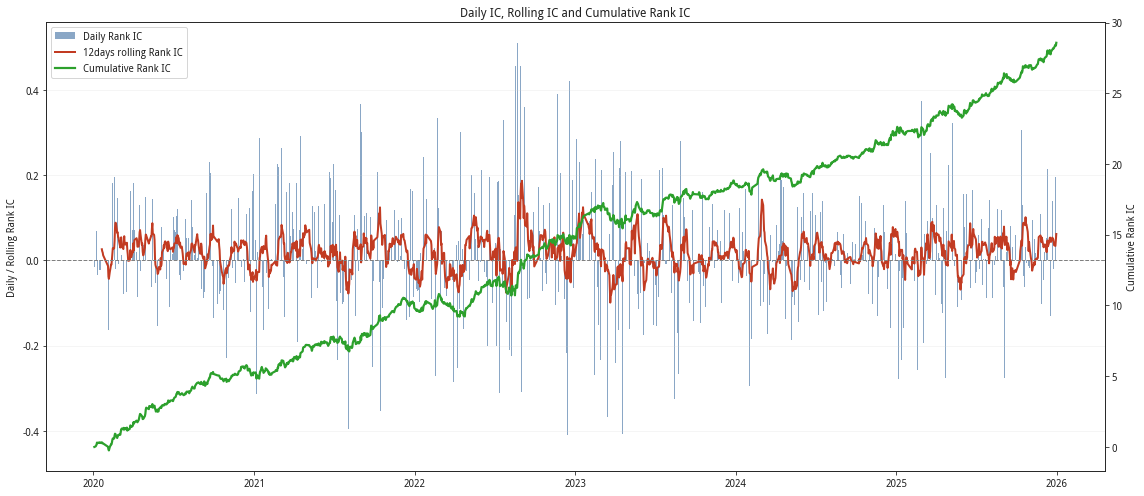

In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_small_board_csad_all_a.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()